In [1]:
import torch
from torch import nn

# Defining the Model
# 7 classes 

"""
The layers that will be used for the CNN
Convolutional Layer, Pooling Layer, and Fully-Connected Layer

"""
class NueralNetworkCNN(nn.Module):
    def __init__(self):
        super().__init__()
        
        # layers of the NN
        self.structure = nn.Sequential(
            # Block 1
            nn.Conv2d(1, 16, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.Conv2d(16, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            
            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            
            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1))  # Collapses any HxW down to 1x1
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128,64),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(64, 7)
        )
        

    def forward(self,x):
        x = self.structure(x)
        logits = self.classifier(x)
        return logits

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else 'cpu'
model = NueralNetworkCNN().to(device= device)

    

In [2]:
""" 
Training The Model

"""

EPOCH = 25  
LEARNING_RATE = 0.001


loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr = LEARNING_RATE
)


def train(dataloader, model , loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()

    train_loss = 0
    correct = 0
    total = 0

    for batch , (X,y) in enumerate(dataloader):
        X, y = X.to(device) , y.to(device)

        # Prediction of the model
        pred = model(X)

        #Loss function is cross entropy
        loss = loss_fn(pred, y)

        # basic backwards propigation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        train_loss += loss.item() * X.size(0)
        correct += (pred.argmax(1) == y).sum().item()
        total += X.size(0)

        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X)
            print(f"loss: {loss:>7f} [{current:5>d}]/{size:>5d}")
    
    train_loss /= total
    accuracy = 100 * correct / total

    print(f"\nTraining Results:")
    print(f"Accuracy: {accuracy:.2f}%")
    print(f"Average Loss: {train_loss:.6f}")

    return train_loss, accuracy

def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    # num_batches = len(dataloader)

    model.eval()
    test_loss, correct = 0, 0

    # Get the emotion names from ImageFolder
    classes = dataloader.dataset.classes
    dataset = dataloader.dataset

    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)

            pred = model(X)

            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).float().sum().item()

    test_loss /= size
    accuracy = 100 * correct / size

    # print(f"Test Error:\n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f}\n")

    # Show predictions from one batch
    # X, y = next(iter(dataloader))
    # X, y = X.to(device), y.to(device)
    
    indicies = torch.randperm(len(dataset))[:8]
    

    for idx in indicies:
        image , label = dataset[idx.item()]

        image = image.unsqueeze(0).to(device)

        pred = model(image)
        predicted = pred.argmax(1).item()

        print(
            f"Prediction : {classes[predicted]} |"
            f"Actual : {classes[label]} |"
        )

    return test_loss, accuracy
    
    # with torch.no_grad():
    #     pred = model(X)
    #     predicted_classes = pred.argmax(1)

    # for i in range(min(8, len(y))):
    #     predicted = classes[predicted_classes[i].item()]
    #     actual = classes[y[i].item()]

    #     print(f"Prediction: {predicted} | Actual: {actual}")




In [3]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parents[1]

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

Training Samples: 28709
Testing Samples: 7178
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Images Shape: torch.Size([32, 1, 48, 48])
Labels Shape: torch.Size([32])
Labels: tensor([0, 6, 2, 4, 0, 4, 5, 2, 2, 4, 3, 2, 3, 4, 5, 2, 5, 2, 0, 2, 2, 4, 2, 6,
        5, 6, 3, 3, 4, 5, 5, 3])


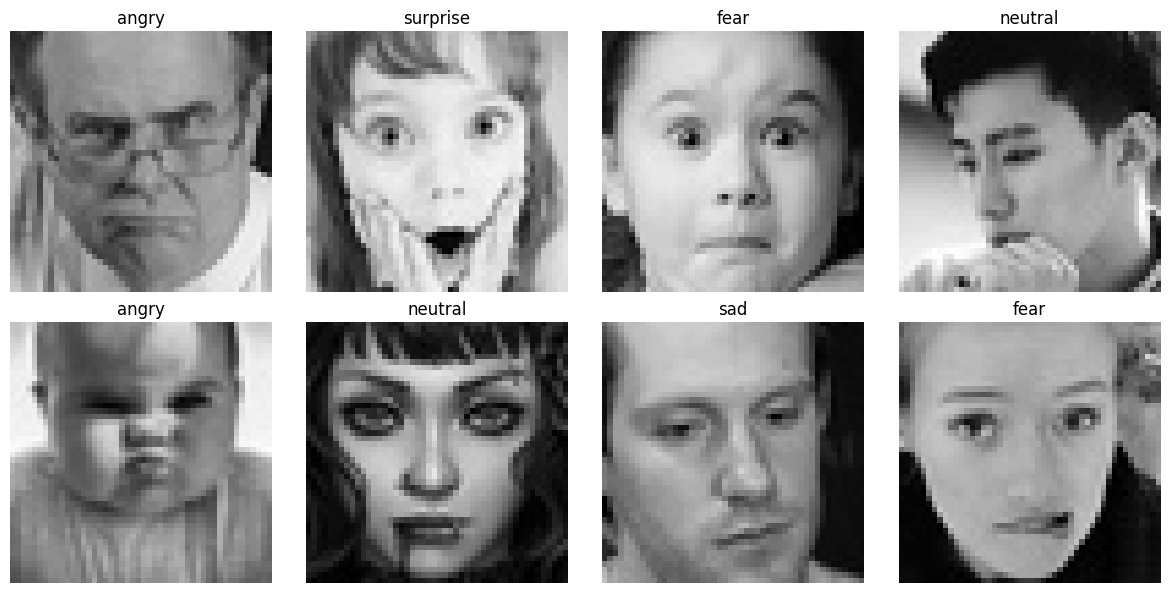

Training Samples: 28709
Testing Samples: 7178
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Images Shape: torch.Size([32, 1, 48, 48])
Labels Shape: torch.Size([32])
Labels: tensor([3, 6, 4, 2, 4, 6, 0, 3, 4, 3, 4, 0, 4, 3, 3, 4, 3, 2, 3, 5, 2, 5, 0, 2,
        5, 2, 4, 4, 3, 3, 3, 2])


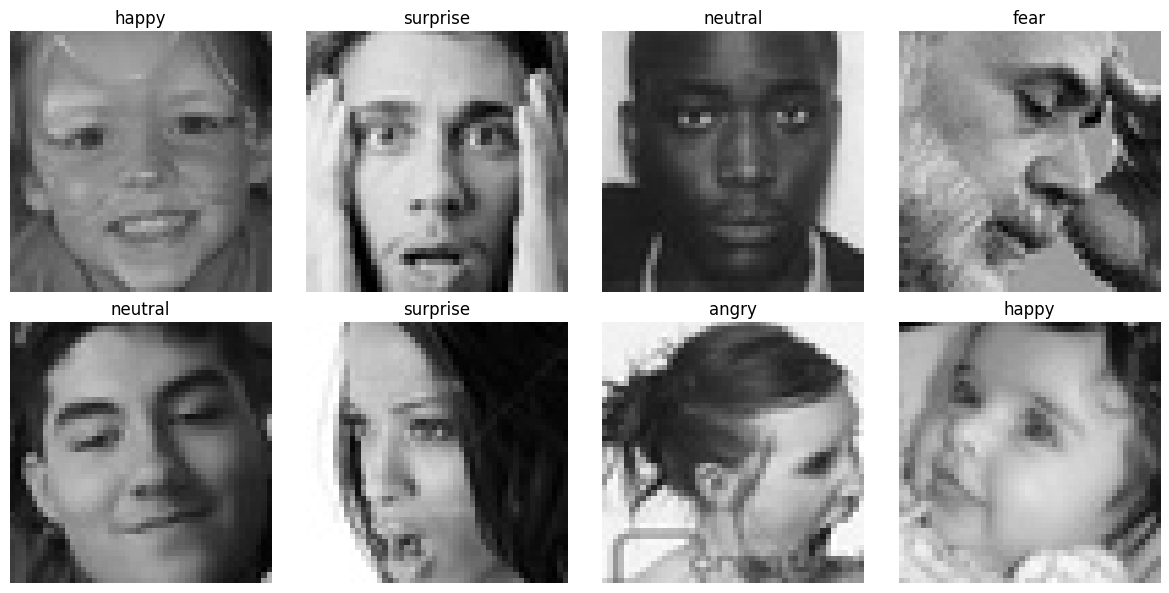

Training batches: 898
Testing batches: 225


In [4]:
import importlib
import src.datasets.datasets as ds

importlib.reload(ds)

train_loader = ds.train_loader
test_loader = ds.test_loader

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

In [5]:
MODEL_PATH = Path("old_model.pth")

model = NueralNetworkCNN().to(device)
if MODEL_PATH.is_file():
    model.load_state_dict(
        torch.load(MODEL_PATH, map_location=device, weights_only=True)
    )
    print("Existing model loaded successfully.")
else:
    print("No existing model found. Training from scratch.")

No existing model found. Training from scratch.


In [6]:
history = {
    "train_loss": [],
    "train_accuracy": [],
    "test_loss": [],
    "test_accuracy": []
}

for t in range(EPOCH):
    print(f"\nEpoch {t + 1}")
    print("-----------------------------")

    train_loss, train_acc = train(
        train_loader, model, loss_fn, optimizer
    )

    test_loss, test_acc = test(
        test_loader, model, loss_fn
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["test_loss"].append(test_loss)
    history["test_accuracy"].append(test_acc)


torch.save(model.state_dict(), "model_v2.pth")


Epoch 1
-----------------------------
loss: 1.953002 [32]/28709
loss: 1.958516 [3232]/28709
loss: 1.962993 [6432]/28709
loss: 1.925688 [9632]/28709
loss: 1.938609 [12832]/28709
loss: 1.964971 [16032]/28709
loss: 1.938717 [19232]/28709
loss: 2.004292 [22432]/28709
loss: 1.982581 [25632]/28709

Training Results:
Accuracy: 14.05%
Average Loss: 1.955726
Prediction : fear |Actual : sad |
Prediction : surprise |Actual : surprise |
Prediction : fear |Actual : fear |
Prediction : fear |Actual : sad |
Prediction : fear |Actual : fear |
Prediction : fear |Actual : happy |
Prediction : fear |Actual : happy |
Prediction : fear |Actual : surprise |

Epoch 2
-----------------------------
loss: 1.942979 [32]/28709
loss: 1.957063 [3232]/28709
loss: 1.989898 [6432]/28709
loss: 1.965611 [9632]/28709
loss: 1.945815 [12832]/28709
loss: 1.949464 [16032]/28709
loss: 1.941952 [19232]/28709
loss: 2.011711 [22432]/28709
loss: 1.947649 [25632]/28709

Training Results:
Accuracy: 14.03%
Average Loss: 1.956141
Pr

KeyboardInterrupt: 